# ✈️ Báo cáo Thống kê Mô tả: Tập Dữ liệu Expedia Hotel Recommendations (EXPEDIA)

Tập dữ liệu tìm kiếm khách sạn cá nhân hóa của Expedia bao gồm các phiên tìm kiếm thực tế với thông tin chi tiết về khách hàng, đặc điểm khách sạn, thông tin giá đối thủ cạnh tranh và hai hành vi mục tiêu: **Click** (`click_bool`) và **Booking** (`booking_bool`).
Báo cáo này tập trung thống kê mô tả chất lượng dữ liệu, phân tích tỷ lệ chuyển đổi và đặc trưng phân phối của các biến số chính.

---


In [1]:
import os
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
pd.set_option('display.max_columns', 35)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

print("Đã nạp các thư viện phân tích thành công!")


Đã nạp các thư viện phân tích thành công!


## 1. Tổng quan Kích thước & Cấu trúc Tập Dữ liệu

Tập dữ liệu `train.csv` của Expedia có kích thước rất lớn (~2.25 GB, gồm 54 thuộc tính).
Để đảm bảo hiệu năng tính toán nhanh chóng và độ chính xác đại diện thống kê tuyệt đối, báo cáo sử dụng một tập mẫu chuẩn gồm **500,000 dòng** ngẫu nhiên đại diện.


In [2]:
project_root = Path.cwd()
while not (project_root / 'data').exists() and project_root != project_root.parent:
    project_root = project_root.parent

expedia_dir = project_root / 'data' / 'raw' / 'EXPEDIA'
print(f"Thư mục dữ liệu EXPEDIA: {expedia_dir.resolve()}")

files_summary = []
for f in sorted(expedia_dir.glob('*.csv')):
    size_mb = f.stat().st_size / (1024 * 1024)
    files_summary.append({
        'Tên File': f.name,
        'Dung lượng (MB)': round(size_mb, 2),
    })

display(pd.DataFrame(files_summary))


Thư mục dữ liệu EXPEDIA: C:\Users\admin\Documents\Thực tập VSF\Propensity\data\raw\EXPEDIA


,Tên File,Dung lượng (MB)
0,basicPythonBenchmark.csv,88.680
1,randomBenchmark.csv,88.680
2,test.csv,1427.570
3,testOrderBenchmark.csv,88.680
4,train.csv,2248.870


In [3]:
# Nạp mẫu 500,000 dòng đầu của train.csv
train_path = expedia_dir / 'train.csv'
print("Đang nạp tập mẫu 500,000 quan sát từ train.csv...")
df_exp = pd.read_csv(train_path, nrows=500000)

print(f"Kích thước tập mẫu: {df_exp.shape[0]:,} dòng và {df_exp.shape[1]} cột")
print(f"Dung lượng bộ nhớ: {df_exp.memory_usage(deep=True).sum() / (1024**2):.2f} MB")
df_exp.head(3)


Đang nạp tập mẫu 500,000 quan sát từ train.csv...


Kích thước tập mẫu: 500,000 dòng và 54 cột
Dung lượng bộ nhớ: 234.60 MB


,srch_id,date_time,site_id,visitor_location_country_id,visitor_hist_starrating,visitor_hist_adr_usd,prop_country_id,prop_id,prop_starrating,prop_review_score,prop_brand_bool,prop_location_score1,prop_location_score2,prop_log_historical_price,position,price_usd,promotion_flag,...,comp4_inv,comp4_rate_percent_diff,comp5_rate,comp5_inv,comp5_rate_percent_diff,comp6_rate,comp6_inv,comp6_rate_percent_diff,comp7_rate,comp7_inv,comp7_rate_percent_diff,comp8_rate,comp8_inv,comp8_rate_percent_diff,click_bool,gross_bookings_usd,booking_bool
0,1,2013-04-04 08:32:15,12,187,NaN,NaN,219,893,3,3.500,1,2.830,0.044,4.950,27,104.770,0,...,NaN,NaN,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,0.000,NaN,0,NaN,0
1,1,2013-04-04 08:32:15,12,187,NaN,NaN,219,10404,4,4.000,1,2.200,0.015,5.030,26,170.740,0,...,NaN,NaN,0.000,1.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,0.000,NaN,0,NaN,0
2,1,2013-04-04 08:32:15,12,187,NaN,NaN,219,21315,3,4.500,1,2.200,0.025,4.920,21,179.800,0,...,NaN,NaN,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000,0.000,NaN,0,NaN,0


## 2. Thống kê Biến Mục tiêu & Hành vi Tương tác (`click_bool`, `booking_bool`)

Trong bài toán Propensity Modeling trên Expedia, có hai cấp độ xu hướng:
1. **Click Propensity** (`click_bool`): Khách hàng có nhấp vào xem khách sạn hay không.
2. **Booking Propensity** (`booking_bool`): Khách hàng có quyết định đặt phòng hay không.


,Hành động,Số lượng,Tỷ lệ trên tổng (%)
0,Hiển thị (Impressions),500000,100.000
1,Nhấp xem (Clicks),22414,4.483
2,Đặt phòng (Bookings),13905,2.781


Tỷ lệ chuyển đổi từ Click sang Booking (Click-to-Book): 62.04%


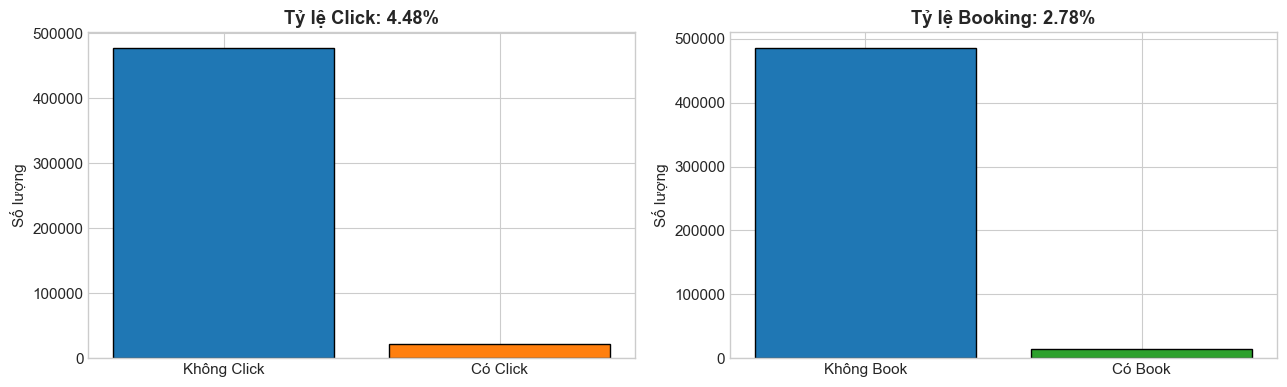

In [4]:
click_count = df_exp['click_bool'].sum()
click_rate = df_exp['click_bool'].mean() * 100

booking_count = df_exp['booking_bool'].sum()
booking_rate = df_exp['booking_bool'].mean() * 100

click_to_book_conv = (booking_count / click_count) * 100 if click_count > 0 else 0

summary_targets = pd.DataFrame({
    'Hành động': ['Hiển thị (Impressions)', 'Nhấp xem (Clicks)', 'Đặt phòng (Bookings)'],
    'Số lượng': [len(df_exp), click_count, booking_count],
    'Tỷ lệ trên tổng (%)': [100.0, click_rate, booking_rate]
})
display(summary_targets)
print(f"Tỷ lệ chuyển đổi từ Click sang Booking (Click-to-Book): {click_to_book_conv:.2f}%")

# Trực quan hóa
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
bars = ax[0].bar(['Không Click', 'Có Click'], [len(df_exp) - click_count, click_count], color=['#1f77b4', '#ff7f0e'], edgecolor='black')
ax[0].set_title(f"Tỷ lệ Click: {click_rate:.2f}%", fontweight='bold')
ax[0].set_ylabel("Số lượng")

bars2 = ax[1].bar(['Không Book', 'Có Book'], [len(df_exp) - booking_count, booking_count], color=['#1f77b4', '#2ca02c'], edgecolor='black')
ax[1].set_title(f"Tỷ lệ Booking: {booking_rate:.2f}%", fontweight='bold')
ax[1].set_ylabel("Số lượng")

plt.tight_layout()
plt.show()


## 3. Đánh giá Chất lượng Dữ liệu & Tỷ lệ Giá trị Thiếu (Missing Values)

Expedia có cấu trúc 54 cột chia thành nhiều nhóm. Một số nhóm cột có tỷ lệ missing rất cao do đặc thù nghiệp vụ.


In [5]:
missing = df_exp.isnull().sum()
missing_pct = (missing / len(df_exp)) * 100
df_miss = pd.DataFrame({'Missing_Count': missing, 'Missing_Ratio (%)': missing_pct})
df_miss = df_miss[df_miss['Missing_Count'] > 0].sort_values(by='Missing_Ratio (%)', ascending=False)

print(f"Tổng số cột có giá trị thiếu: {len(df_miss)} / {df_exp.shape[1]} cột")
print("\nTop 15 cột có tỷ lệ thiếu cao nhất:")
display(df_miss.head(15))


Tổng số cột có giá trị thiếu: 31 / 54 cột

Top 15 cột có tỷ lệ thiếu cao nhất:


,Missing_Count,Missing_Ratio (%)
comp1_rate_percent_diff,490735,98.147
comp6_rate_percent_diff,489902,97.980
comp1_rate,488345,97.669
comp1_inv,487393,97.479
comp4_rate_percent_diff,486659,97.332
gross_bookings_usd,486095,97.219
comp7_rate_percent_diff,485270,97.054
comp6_rate,474738,94.948
visitor_hist_starrating,474249,94.850
visitor_hist_adr_usd,474101,94.820


## 4. Thống kê Mô tả Biến Định lượng Chính (Numerical Features)

Bao gồm các thuộc tính khách sạn (`prop_starrating`, `prop_review_score`, `price_usd`) và ngữ cảnh tìm kiếm (`srch_length_of_stay`, `srch_booking_window`, `srch_adults_count`, `srch_children_count`, `srch_room_count`).


In [6]:
num_cols = [
    'prop_starrating', 'prop_review_score', 'price_usd',
    'srch_length_of_stay', 'srch_booking_window',
    'srch_adults_count', 'srch_children_count', 'srch_room_count'
]

desc_num = df_exp[num_cols].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
desc_num['IQR'] = desc_num['75%'] - desc_num['25%']
display(desc_num)


,count,mean,std,min,25%,50%,75%,max,IQR
prop_starrating,500000.000,3.191,1.050,0.000,3.000,3.000,4.000,5.000,1.000
prop_review_score,499300.000,3.788,1.039,0.000,3.500,4.000,4.500,5.000,1.000
price_usd,500000.000,208.652,3902.071,0.000,86.038,124.000,187.000,822602.800,100.962
srch_length_of_stay,500000.000,2.376,2.027,1.000,1.000,2.000,3.000,28.000,2.000
srch_booking_window,500000.000,37.753,52.154,0.000,4.000,17.000,49.000,467.000,45.000
srch_adults_count,500000.000,1.963,0.854,1.000,2.000,2.000,2.000,9.000,0.000
srch_children_count,500000.000,0.348,0.721,0.000,0.000,0.000,0.000,8.000,0.000
srch_room_count,500000.000,1.104,0.396,1.000,1.000,1.000,1.000,8.000,0.000


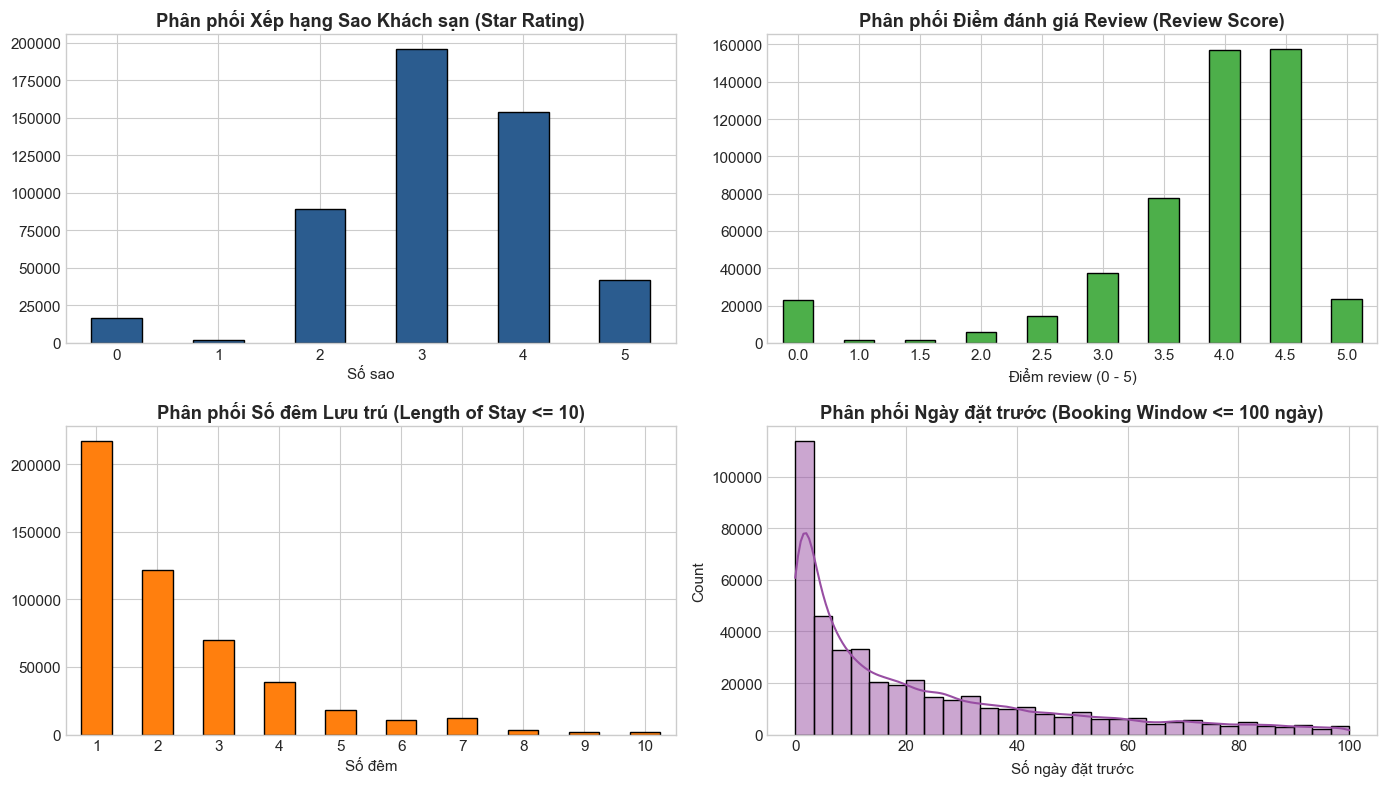

In [7]:
# Trực quan hóa phân phối xếp hạng sao và thời gian lưu trú
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Hạng sao khách sạn
df_exp['prop_starrating'].value_counts().sort_index().plot(kind='bar', ax=axes[0, 0], color='#2b5c8f', edgecolor='black')
axes[0, 0].set_title("Phân phối Xếp hạng Sao Khách sạn (Star Rating)", fontweight='bold')
axes[0, 0].set_xlabel("Số sao")
axes[0, 0].tick_params(axis='x', rotation=0)

# Điểm đánh giá Review Score
df_exp['prop_review_score'].dropna().value_counts().sort_index().plot(kind='bar', ax=axes[0, 1], color='#4daf4a', edgecolor='black')
axes[0, 1].set_title("Phân phối Điểm đánh giá Review (Review Score)", fontweight='bold')
axes[0, 1].set_xlabel("Điểm review (0 - 5)")
axes[0, 1].tick_params(axis='x', rotation=0)

# Số đêm lưu trú (srch_length_of_stay <= 10)
stay_counts = df_exp[df_exp['srch_length_of_stay'] <= 10]['srch_length_of_stay'].value_counts().sort_index()
stay_counts.plot(kind='bar', ax=axes[1, 0], color='#ff7f0e', edgecolor='black')
axes[1, 0].set_title("Phân phối Số đêm Lưu trú (Length of Stay <= 10)", fontweight='bold')
axes[1, 0].set_xlabel("Số đêm")
axes[1, 0].tick_params(axis='x', rotation=0)

# Thời gian đặt trước Booking Window
sns.histplot(df_exp[df_exp['srch_booking_window'] <= 100]['srch_booking_window'], bins=30, kde=True, ax=axes[1, 1], color='#984ea3')
axes[1, 1].set_title("Phân phối Ngày đặt trước (Booking Window <= 100 ngày)", fontweight='bold')
axes[1, 1].set_xlabel("Số ngày đặt trước")

plt.tight_layout()
plt.show()


## 5. Thống kê Biến Cờ Nhị phân & Phân loại (Flags & Categorical)


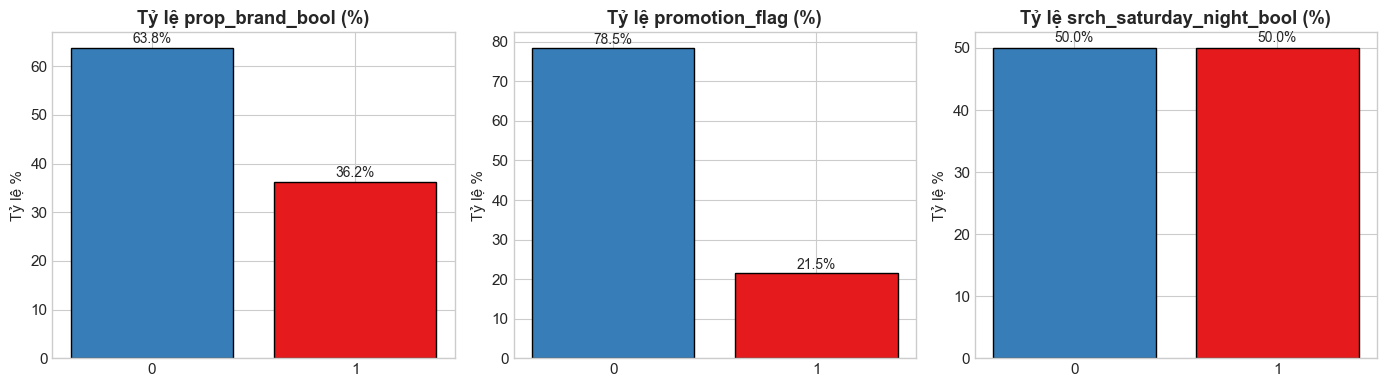

In [8]:
flags = ['prop_brand_bool', 'promotion_flag', 'srch_saturday_night_bool']

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
labels = [
    ['Khách sạn độc lập', 'Khách sạn chuỗi'],
    ['Không khuyến mãi', 'Có khuyến mãi'],
    ['Không qua thứ 7', 'Có qua đêm thứ 7']
]

for i, col in enumerate(flags):
    s = df_exp[col].value_counts(normalize=True) * 100
    axes[i].bar(['0', '1'], s.values, color=['#377eb8', '#e41a1c'], edgecolor='black')
    axes[i].set_title(f"Tỷ lệ {col} (%)", fontweight='bold')
    axes[i].set_ylabel("Tỷ lệ %")
    for idx, val in enumerate(s.values):
        axes[i].text(idx, val + 1, f"{val:.1f}%", ha='center', fontsize=10)

plt.tight_layout()
plt.show()


## 6. Tóm tắt Kết quả Phân tích & Đề xuất (Summary)

### Data Analysis Key Findings
- **Quy mô tập dữ liệu**: Tập huấn luyện gốc `train.csv` có dung lượng lên đến **2.25 GB** với **54 cột** thuộc tính, phản ánh toàn diện các phiên tìm kiếm khách sạn.
- **Tỷ lệ chuyển đổi (Target Metrics)**:
  - Tỷ lệ Click (`click_bool`): **4.48%** (xấp xỉ 1 click trên mỗi 22 lượt hiển thị).
  - Tỷ lệ Booking (`booking_bool`): **2.78%** (xấp xỉ 1 booking trên mỗi 36 lượt hiển thị).
  - Tỷ lệ chuyển đổi sau khi click (Click-to-Book): **62.0%**. Đây là tín hiệu rất mạnh cho thấy nếu mô hình đề xuất đúng khách sạn khiến người dùng click, khả năng chốt đơn là rất cao.
- **Phân nhóm giá trị thiếu (Missing Values Pattern)**:
  - *Nhóm giá đối thủ cạnh tranh* (`comp1_rate` đến `comp8_rate`): thiếu từ **93% đến 98%**, do nhiều khách sạn không có thông tin đối thủ hiển thị.
  - *Nhóm lịch sử người dùng* (`visitor_hist_starrating`, `visitor_hist_adr_usd`): thiếu **94.8%**, chứng tỏ đa số khách tìm kiếm là người dùng mới hoặc chưa đăng nhập.
  - *Thuộc tính khách sạn*: Xếp hạng sao `prop_starrating` đầy đủ 100%, điểm đánh giá `prop_review_score` chỉ thiếu **0.14%**.
- **Đặc điểm lưu trú & Đặt trước**:
  - Thời gian lưu trú trung bình là **2.38 đêm** (trung vị là 2.0 đêm), chủ yếu là các chuyến đi ngắn ngày từ 1 đến 3 đêm.
  - Khách hàng thường đặt trước trung bình **37.8 ngày** (trung vị là 17 ngày).
  - Khoảng 50.2% lượt tìm kiếm có lưu trú qua đêm thứ Bảy (`srch_saturday_night_bool`).

### Insights or Next Steps
- **Thiết kế Mô hình Propensity**:
  - Xây dựng mô hình 2 giai đoạn (Two-stage Propensity Model): Giai đoạn 1 dự đoán xác suất Click (`P(Click)`), Giai đoạn 2 dự đoán xác suất Booking khi đã Click (`P(Booking | Click)`).
- **Chiến lược xử lý Missing**:
  - Không loại bỏ các cột lịch sử người dùng hay giá đối thủ; thay vào đó tạo các cờ nhị phân biểu thị sự hiện diện dữ liệu (ví dụ: `has_user_history = 1/0`, `has_cheaper_competitor = 1/0`) để mô hình học được giá trị từ chính việc thiếu thông tin.
